In [1]:

import sys

from datetime import datetime

# Laboratory Python packages
package_dir = r"D:\Control\PythonPackages"

if package_dir not in sys.path:
    sys.path.append(package_dir)

import Components as comp

# Import the HydraHarp driver from Lab 3
from lab_hydraharp import HydraHarp

# Check driver API before connecting hardware
required_methods = ["start", "complete", "stop_read"]

missing = [
    method for method in required_methods
    if not hasattr(HydraHarp, method)
]

if missing:
    raise RuntimeError(
        "HydraHarp driver is missing methods: "
        + ", ".join(missing)
    )

print("HydraHarp driver imported successfully.")

# Initialise devices once
hh = HydraHarp()
print("HydraHarp initialised.")

laser = comp.Toptica_Laser()
print("Toptica Laser connected.")


HydraHarp driver imported successfully.
HydraHarp initialised.
Toptica Laser connected.


In [2]:

# %%
def measure_histogram(hh, seconds=20, channel=0):
    """Acquire a fresh HydraHarp histogram."""

    if not 0 <= channel < hh.channels:
        raise ValueError("Invalid input channel")

    hh.start(seconds)

    try:
        deadline = time.monotonic() + seconds + 10

        while not hh.complete():
            if time.monotonic() > deadline:
                raise TimeoutError(
                    "HydraHarp acquisition timed out"
                )

            time.sleep(0.05)

    finally:
        result = hh.stop_read()

    counts = np.asarray(
        result["histograms"][channel],
        dtype=np.uint32
    )

    delay_ns = (
        np.arange(counts.size)
        * hh.settings["resolution_ps"]
        / 1000
    )

    return delay_ns, counts, result


def make_data_folder(base_directory=r"D:\Data"):

    now = datetime.now()

    folder = os.path.join(
        base_directory,
        now.strftime("%Y"),
        now.strftime("%Y%m"),
        now.strftime("%Y%m%d"),
        "lab4"
    )

    os.makedirs(folder, exist_ok=True)

    return folder


print("Measurement functions ready.")


Measurement functions ready.


NameError: name 'make_data_folder' is not defined

LAB4 ND2 CONTINUATION
Range: 32.60 - 32.80 mW
Step: 0.05 mW
Total points: 5
Saving to: D:\Data\2026\202611\20261109\lab4
Powers: [32.6  32.65 32.7  32.75 32.8 ]
[1/5] Measuring 32.60 mW


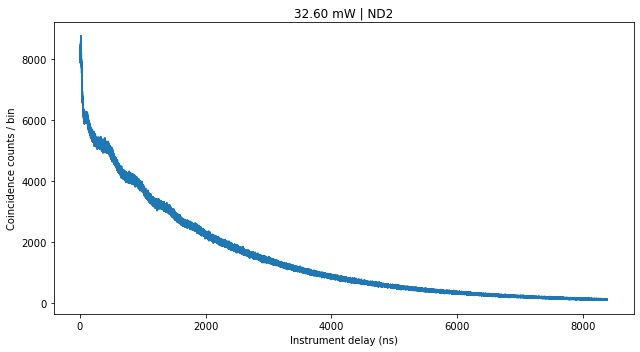

Finished 32.60 mW
[2/5] Measuring 32.65 mW


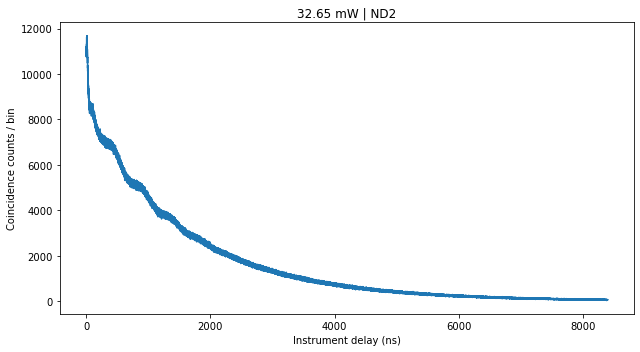

Finished 32.65 mW
[3/5] Measuring 32.70 mW


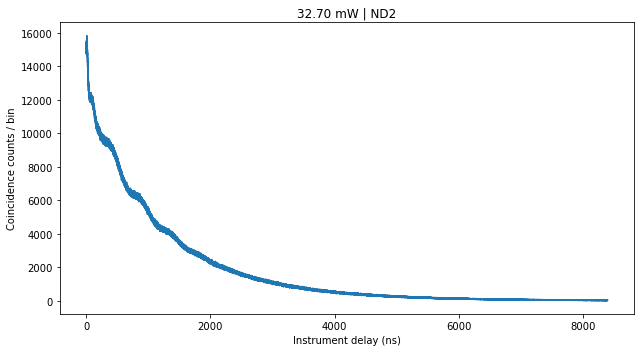

Finished 32.70 mW
[4/5] Measuring 32.75 mW


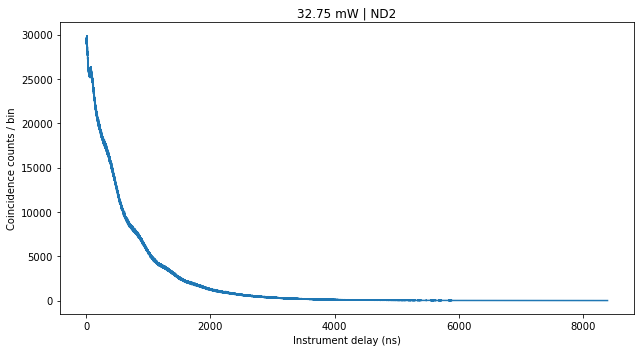

Finished 32.75 mW
[5/5] Measuring 32.80 mW


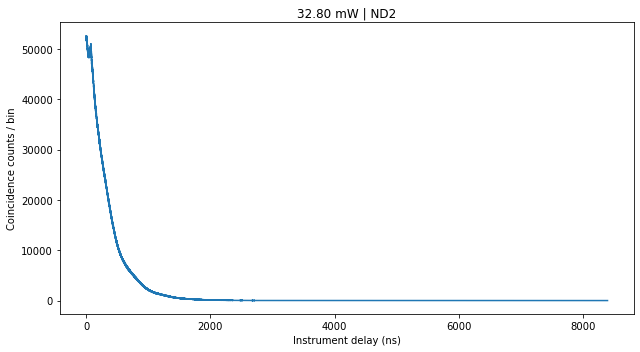

Finished 32.80 mW
LAB4 ND2 CONTINUATION COMPLETE
Data saved to: D:\Data\2026\202611\20261109\lab4


In [4]:

# %%
# --------------------------------------------------
# LAB4 - ND2 SCAN: 32.200 to 32.550 mW
# --------------------------------------------------


# %%
# --------------------------------------------------
# LAB4 - ND2 CONTINUATION SCAN
# 32.60 to 32.80 mW, step 0.05 mW
# --------------------------------------------------

import os
import numpy as np
import matplotlib.pyplot as plt
import time
from IPython.display import display

P_min = 32.60
P_max = 32.80
P_step = 0.05

ND = "ND2"

acquisition_time = 20
settling_time = 2

# Use the SAME folder as the previous Lab4 scan
folder = make_data_folder()

# Generate 5 measurement points
powers = np.round(
    np.arange(5) * P_step + P_min,
    2
)

print("LAB4 ND2 CONTINUATION")
print(f"Range: {P_min:.2f} - {P_max:.2f} mW")
print(f"Step: {P_step:.2f} mW")
print(f"Total points: {len(powers)}")
print(f"Saving to: {folder}")
print("Powers:", powers)

# Check for existing files before starting
for power in powers:
    name = f"{power:.2f}mW_{ND}"

    for ext in (".npz", ".png"):
        path = os.path.join(folder, name + ext)

        if os.path.exists(path):
            raise FileExistsError(
                f"File already exists: {path}"
            )

# --------------------------------------------------
# Measurement loop
# --------------------------------------------------

for i, power in enumerate(powers):

    print(
        f"[{i+1}/{len(powers)}] "
        f"Measuring {power:.2f} mW",
        flush=True
    )

    # Set laser power (mW -> W)
    laser.set(float(power) / 1000)

    # Wait for laser to stabilise
    time.sleep(settling_time)

    # Acquire histogram
    delay_ns, counts, result = measure_histogram(
        hh,
        seconds=acquisition_time,
        channel=0
    )

    name = f"{power:.2f}mW_{ND}"

    # Save raw data
    np.savez(
        os.path.join(folder, name + ".npz"),
        delay_ns=delay_ns,
        counts=counts,
        power_mW=power,
        ND=ND,
        acquisition_time_s=acquisition_time
    )

    # Plot histogram
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(delay_ns, counts)

    ax.set_xlabel("Instrument delay (ns)")
    ax.set_ylabel("Coincidence counts / bin")
    ax.set_title(f"{power:.2f} mW | {ND}")

    fig.tight_layout()

    fig.savefig(
        os.path.join(folder, name + ".png"),
        dpi=150
    )

    display(fig)
    plt.close(fig)

    print(
        f"Finished {power:.2f} mW",
        flush=True
    )

print("LAB4 ND2 CONTINUATION COMPLETE")
print("Data saved to:", folder)



LAB4 ND4 SCAN
Range: 33.00 - 33.40 mW
Step: 0.05 mW
Total points: 9
ND filter: ND4
Saving to: D:\Data\2026\202611\20261109\lab4\ND4
Powers: [33.   33.05 33.1  33.15 33.2  33.25 33.3  33.35 33.4 ]
New measurements to acquire: 9
[1/9] Measuring 33.00 mW
Saved: D:\Data\2026\202611\20261109\lab4\ND4\33.00mW_ND4.npz


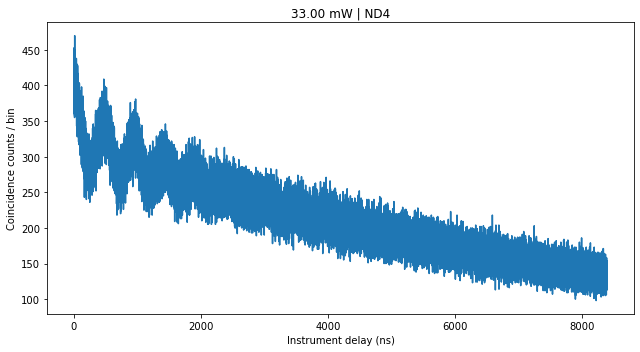

Finished 33.00 mW
[2/9] Measuring 33.05 mW
Saved: D:\Data\2026\202611\20261109\lab4\ND4\33.05mW_ND4.npz


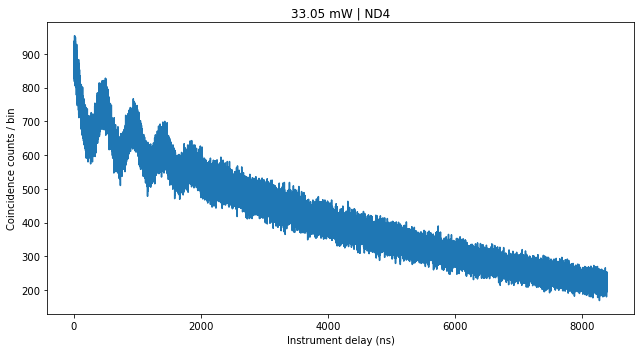

Finished 33.05 mW
[3/9] Measuring 33.10 mW
Saved: D:\Data\2026\202611\20261109\lab4\ND4\33.10mW_ND4.npz


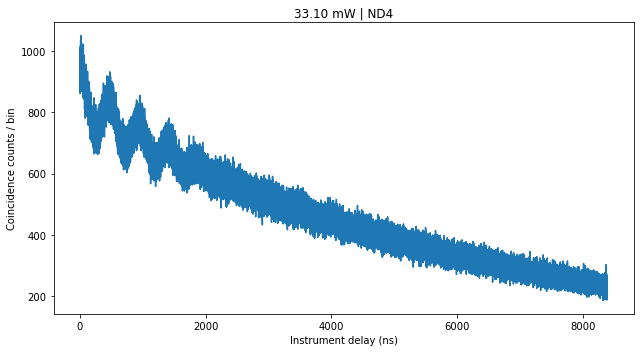

Finished 33.10 mW
[4/9] Measuring 33.15 mW
Saved: D:\Data\2026\202611\20261109\lab4\ND4\33.15mW_ND4.npz


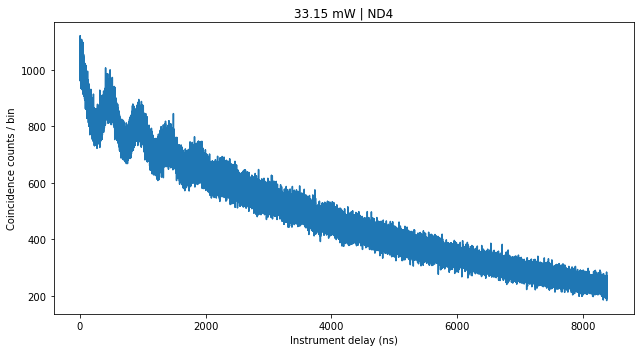

Finished 33.15 mW
[5/9] Measuring 33.20 mW
Saved: D:\Data\2026\202611\20261109\lab4\ND4\33.20mW_ND4.npz


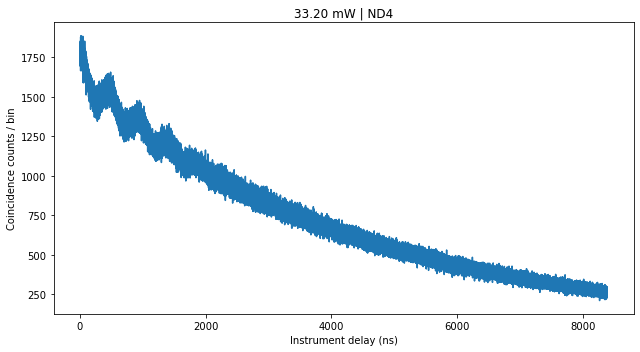

Finished 33.20 mW
[6/9] Measuring 33.25 mW
Saved: D:\Data\2026\202611\20261109\lab4\ND4\33.25mW_ND4.npz


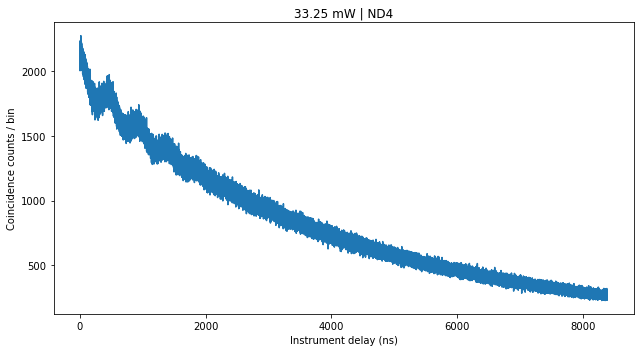

Finished 33.25 mW
[7/9] Measuring 33.30 mW
Saved: D:\Data\2026\202611\20261109\lab4\ND4\33.30mW_ND4.npz


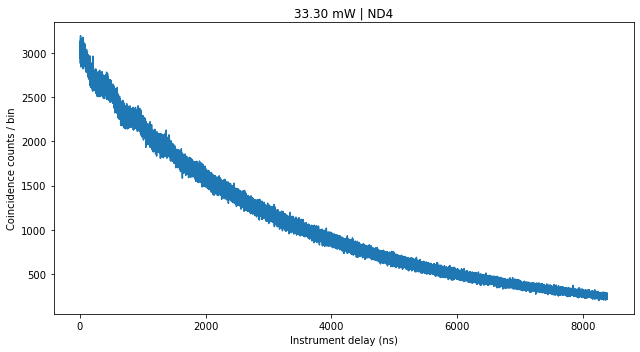

Finished 33.30 mW
[8/9] Measuring 33.35 mW
Saved: D:\Data\2026\202611\20261109\lab4\ND4\33.35mW_ND4.npz


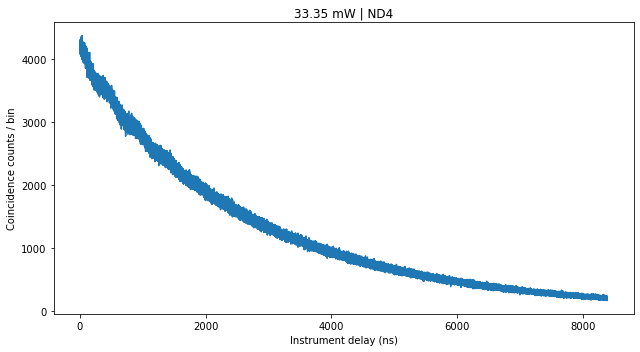

Finished 33.35 mW
[9/9] Measuring 33.40 mW
Saved: D:\Data\2026\202611\20261109\lab4\ND4\33.40mW_ND4.npz


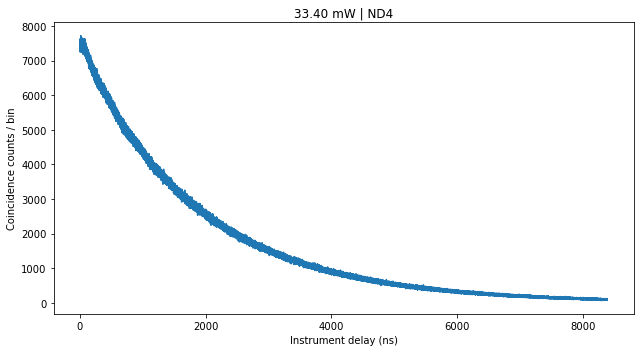

Finished 33.40 mW
LAB4 ND4 SCAN COMPLETE
New measurements: 9
Data saved to: D:\Data\2026\202611\20261109\lab4\ND4


In [3]:




# %%
# --------------------------------------------------
# LAB4 - ND4 SCAN
# 33.00 to 33.40 mW, step 0.05 mW
# --------------------------------------------------

import os
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# --------------------------------------------------
# Scan settings
# --------------------------------------------------

P_min = 33.00
P_max = 33.40
P_step = 0.05

ND = "ND4"

acquisition_time = 20
settling_time = 2
channel = 0

# --------------------------------------------------
# Create ND4 folder inside existing lab4 folder
# --------------------------------------------------

folder = r"D:\Data\2026\202611\20261109\lab4\ND4"

os.makedirs(folder, exist_ok=True)

# --------------------------------------------------
# Generate measurement points
# --------------------------------------------------

powers = np.round(
    P_min + np.arange(
        int(round((P_max - P_min) / P_step)) + 1
    ) * P_step,
    2
)

print("=" * 50)
print("LAB4 ND4 SCAN")
print(f"Range: {P_min:.2f} - {P_max:.2f} mW")
print(f"Step: {P_step:.2f} mW")
print(f"Total points: {len(powers)}")
print(f"ND filter: {ND}")
print(f"Saving to: {folder}")
print("Powers:", powers)
print("=" * 50)

# --------------------------------------------------
# Identify measurements not yet saved
# --------------------------------------------------

pending = []

for power in powers:

    name = f"{power:.2f}mW_{ND}"
    npz_path = os.path.join(folder, name + ".npz")

    if os.path.isfile(npz_path):
        print(f"Skipping existing: {name}")
    else:
        pending.append(power)

print(f"New measurements to acquire: {len(pending)}")

# --------------------------------------------------
# Confirm hardware setup
# --------------------------------------------------

if pending:
    confirmation = input(
        "Confirm ND4 installed and detector count rate safe. "
        "Type YES to start: "
    )

    if confirmation != "YES":
        raise RuntimeError("Scan cancelled.")

# --------------------------------------------------
# Measurement loop
# --------------------------------------------------

for i, power in enumerate(pending):

    print(
        f"[{i+1}/{len(pending)}] "
        f"Measuring {power:.2f} mW",
        flush=True
    )

    # Set laser power (mW -> W)
    laser.set(float(power) / 1000)

    # Wait for laser stabilisation
    time.sleep(settling_time)

    # Acquire HydraHarp histogram
    delay_ns, counts, result = measure_histogram(
        hh,
        seconds=acquisition_time,
        channel=channel
    )

    # --------------------------------------------------
    # Save data
    # --------------------------------------------------

    name = f"{power:.2f}mW_{ND}"

    npz_path = os.path.join(folder, name + ".npz")
    png_path = os.path.join(folder, name + ".png")

    if os.path.exists(npz_path):
        raise FileExistsError(
            f"Refusing to overwrite: {npz_path}"
        )

    np.savez(
        npz_path,
        delay_ns=delay_ns,
        counts=counts,
        power_mW=power,
        ND=ND,
        acquisition_time_s=acquisition_time,
        channel=channel
    )

    print(f"Saved: {npz_path}", flush=True)

    # --------------------------------------------------
    # Plot histogram
    # --------------------------------------------------

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(delay_ns, counts)

    ax.set_xlabel("Instrument delay (ns)")
    ax.set_ylabel("Coincidence counts / bin")
    ax.set_title(f"{power:.2f} mW | {ND}")

    fig.tight_layout()

    if not os.path.exists(png_path):
        fig.savefig(png_path, dpi=150)

    display(fig)
    plt.close(fig)

    print(
        f"Finished {power:.2f} mW",
        flush=True
    )

# --------------------------------------------------
# Scan complete
# --------------------------------------------------

print("=" * 50)
print("LAB4 ND4 SCAN COMPLETE")
print(f"New measurements: {len(pending)}")
print(f"Data saved to: {folder}")
print("=" * 50)


